# 06 - Network Analysis: Centrality + Visualisation

This notebook performs **centrality analysis** on the YouTube subscription network and
produces a publication-quality visualisation. We identify the core nodes (hubs) using
multiple centrality measures and compare the results.

### Centrality Methods

| Method | Description |
|--------|-------------|
| **Degree** | Fraction of nodes connected to a given node |
| **Betweenness** | Fraction of shortest paths passing through a node |
| **Eigenvector** | Influence based on connections to other influential nodes |
| **PageRank** | Recursive importance (used by Google's original algorithm) |
| **K-core** | Membership in the maximum k-core (densest subgraph) |
| **Weighted** | Degree multiplied by subscriber count (node size) |

The top 5% of nodes by each method are identified as core nodes. Consensus across
methods strengthens the classification.

In [1]:
import sys
sys.path.insert(0, '..')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from src.analysis.network_analysis import identify_core_nodes
from src.visualization.network_plots import visualize_network_from_processed_data
from src.utils.config import get_data_path, get_results_path

## Configuration

| Parameter | Description | Value |
|-----------|-------------|-------|
| `processed_data_path` | Pre-processed network data (JSON) | `data/raw/processed_network_data.json` |
| `top_percent` | Percentage of nodes to classify as core | 5 |
| `output_path` | Path to save the network visualisation | `results/figures/youtube_network.png` |

In [2]:
PROCESSED_DATA_PATH = str(get_data_path('raw') / 'processed_network_data.json')
OUTPUT_PATH = str(get_results_path('figures') / 'youtube_network.png')
TOP_PERCENT = 5

print(f"Processed data: {PROCESSED_DATA_PATH}")
print(f"Output path:    {OUTPUT_PATH}")
print(f"Top percent:    {TOP_PERCENT}%")
print(f"Data exists:    {os.path.exists(PROCESSED_DATA_PATH)}")

Processed data: /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/data/raw/processed_network_data.json
Output path:    /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/results/figures/youtube_network.png
Top percent:    5%
Data exists:    True


## Run Centrality Analysis

The `identify_core_nodes` function builds a NetworkX graph from the processed JSON data
and computes centrality scores using all six methods. For each method, the top 5% of
nodes are returned with their labels and scores.

In [3]:
results = identify_core_nodes(
    processed_data_path=PROCESSED_DATA_PATH,
    methods=['degree', 'betweenness', 'eigenvector', 'pagerank', 'kcore', 'weighted'],
    top_percent=TOP_PERCENT,
)

for method, nodes in results.items():
    print(f"\n=== {method.upper()} (top {TOP_PERCENT}%) ===")
    for node_id, label, score in nodes:
        print(f"  {label:30s}  score={score:.6f}")

Graph: 5693 nodes, 588577 edges

=== DEGREE (top 5%) ===
  Aaj Tak HD                      score=0.136683
  Wonder Of Stories               score=0.135980
  Rajasthani Chamak Music         score=0.135980
  MAA MAA TV - Hindi Stories      score=0.135805
  News Nation                     score=0.135805
  Punjab Kesari TV                score=0.135629
  Unani Nuskhe                    score=0.135453
  DRJ Records Movies              score=0.135278
  Jok                             score=0.135102
  KADAK                           score=0.135102
  Farmani naaz                    score=0.135102
  Zee Hindustan                   score=0.135102
  Josh - Hindi Kahaniya           score=0.134926
  BBC News Hindi                  score=0.134926
  NewsClickin                     score=0.134926
  Jadu Tv - Hindi Stories         score=0.134926
  ABP NEWS                        score=0.134926
  inKhabar                        score=0.134926
  BeautyExperts                   score=0.134926
  MAKE JOKE 

## Consensus Analysis

We determine which nodes appear as core across multiple centrality methods.
Nodes identified by 4+ methods are strong hub candidates.

In [4]:
from collections import Counter

# Count how often each node appears across methods
node_counts = Counter()
node_labels = {}
for method, nodes in results.items():
    for node_id, label, score in nodes:
        node_counts[node_id] += 1
        node_labels[node_id] = label

consensus_df = pd.DataFrame([
    {'node_id': nid, 'label': node_labels[nid], 'methods_count': count}
    for nid, count in node_counts.most_common()
])

print(f"Nodes appearing in 4+ methods: {len(consensus_df[consensus_df['methods_count'] >= 4])}")
print(f"Nodes appearing in all 6 methods: {len(consensus_df[consensus_df['methods_count'] == 6])}")
print()
print(consensus_df.head(20).to_string(index=False))

Nodes appearing in 4+ methods: 42
Nodes appearing in all 6 methods: 0

               node_id                                   label  methods_count
              Bbchindi                          BBC News Hindi              5
NyeSfUfffmJXwA2_tmNG9A                        The Screen Patti              5
               SonyLIV                                 SonyLIV              5
BhStnvUsWCMvAUj7UGj0Wg                      DRJ Records Movies              4
Ojgc1p2hJ4GZi6pQQoXWYQ        Oneindia Hindi | वनइंडिया हिन्दी              4
EI_dcoGYhMLyYpXok6jmog    PopCorn /- Funny Hindi Comedy Videos              4
7ot9AlDim4UKhz3TP_WWnw                        Majedar Kahaniya              4
S2E8XulDhyAw3ji7ggg1EQ  Golden TV - Funny Hindi Comedy Stories              4
tArm3-faI7bOK-6J-H-SPA Learnex - English lessons through Hindi              4
           ShemarooEnt                                Shemaroo              4
AUNFgpgVisKPL3yq_-Nj-Q                                News Tak         

## Centrality Score Comparison

A bar chart showing how the top nodes rank across different centrality methods.

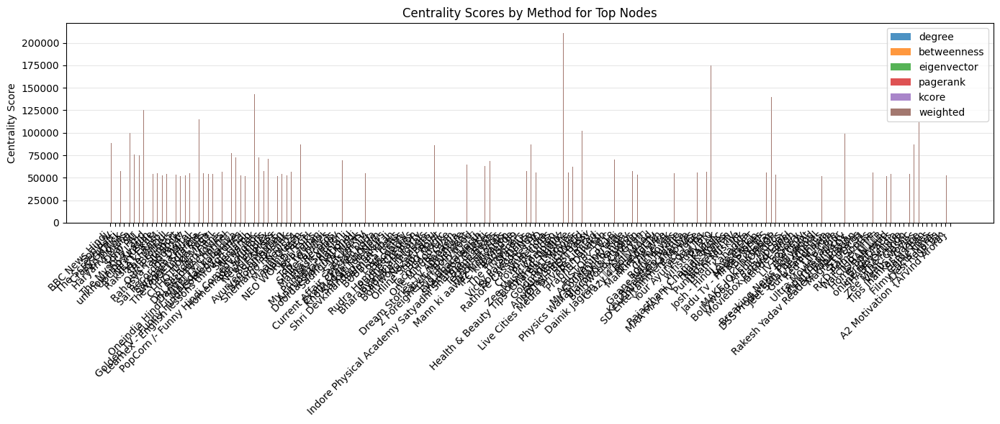

In [5]:
# Build a comparison DataFrame for consensus nodes
top_nodes = consensus_df[consensus_df['methods_count'] >= 3]['node_id'].tolist()

comparison_data = []
for method, nodes in results.items():
    for node_id, label, score in nodes:
        if node_id in top_nodes:
            comparison_data.append({'node_id': node_id, 'label': label, 'method': method, 'score': score})

if comparison_data:
    comp_df = pd.DataFrame(comparison_data)
    fig, ax = plt.subplots(figsize=(14, 6))
    labels_order = consensus_df[consensus_df['methods_count'] >= 3].sort_values('methods_count', ascending=False)['label'].tolist()
    methods = list(results.keys())

    x = np.arange(len(labels_order))
    width = 0.12
    for i, method in enumerate(methods):
        sub = comp_df[comp_df['method'] == method]
        heights = []
        for label in labels_order:
            match = sub[sub['label'] == label]
            heights.append(match['score'].values[0] if len(match) else 0)
        ax.bar(x + i * width, heights, width, label=method, alpha=0.8)

    ax.set_xticks(x + width * len(methods) / 2)
    ax.set_xticklabels(labels_order, rotation=45, ha='right')
    ax.set_ylabel('Centrality Score')
    ax.set_title('Centrality Scores by Method for Top Nodes')
    ax.legend()
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()
else:
    print("No consensus nodes found.")

## Network Visualisation

Generate a publication-quality visualisation of the YouTube subscription network.
Nodes are coloured by community membership and sized by subscriber count.
Only the largest nodes (top 5%) are labelled to avoid clutter.

In [6]:
visualize_network_from_processed_data(
    processed_data_path=PROCESSED_DATA_PATH,
    output_path=OUTPUT_PATH,
    dpi=300,
)

Graph: 5693 nodes, 588577 edges
Saved to /Users/shalemsuma/Desktop/College/Capstone/interest-heterogeneity-network-formation/results/figures/youtube_network.png


In [7]:
# Display the saved figure inline
if os.path.exists(OUTPUT_PATH):
    from IPython.display import Image, display
    display(Image(filename=OUTPUT_PATH, width=800))
else:
    print(f"Figure not found at: {OUTPUT_PATH}")